# Data Exploration

## Description of all datasets
These datasets contain information about temperature measurements done around the world, starting in 1750 for average land temperatures and in 1850 for max and min land temperatures and global ocean and land temperatures.<br>
All measurements are in celsius.<br>
The uncertainty gives the 95% confidence interval around the measurement. So if a measurement of 1 degree is done with an uncertainty of 0.5, that means that with 95% confidence, the actual temperature is between 0.5 and 1.5.<br>

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import create_engine

In [2]:
def decompose_date(df: pd.DataFrame) -> pd.DataFrame:
    df["year"] = df["dt"].dt.year
    df["month"] = df["dt"].dt.month
    return df

engine = create_engine(
    "mysql+pymysql://root@localhost:3306/climate_watch"
)
df_city = pd.read_sql("SELECT * FROM GlobalLandTemperaturesByCity", con=engine, parse_dates=["dt"])
df_city = decompose_date(df_city)

df_country = pd.read_sql("SELECT * FROM GlobalLandTemperaturesByCountry", con=engine, parse_dates=["dt"])
df_country = decompose_date(df_country)

df_major_city = pd.read_sql("SELECT * FROM GlobalLandTemperaturesByMajorCity", con=engine, parse_dates=["dt"])
df_major_city = decompose_date(df_major_city)

df_state = pd.read_sql("SELECT * FROM GlobalLandTemperaturesByState", con=engine, parse_dates=["dt"])
df_state = decompose_date(df_state)

df_global = pd.read_sql("SELECT * FROM GlobalTemperatures", con=engine, parse_dates=["dt"])
df_global = decompose_date(df_global)

## City data

The city data consists of 7 columns: 
- Date of measurement
- Average temperature measured
- Uncertainty of temperature measurement
- City name
- Country name
- Latitude of measurement
- Longitude of measurement

Almost all values are present from 1900.

In [3]:
df_city["n"] = None
df_nr_of_empty_values = df_city.isna().groupby(df_city["year"]).sum()
df_nr_of_empty_values["nan_ratio"] = round(df_nr_of_empty_values["AverageTemperature"] / df_nr_of_empty_values["n"], 2)
with pd.option_context("Display.max_rows", 271):
    display(df_nr_of_empty_values[["AverageTemperature", "n", "nan_ratio"]])

df_nr_of_empty_values["nan_ratio"].mean()

,AverageTemperature,n,nan_ratio
year,,,
1743,706,1412,0.50
1744,2122,8472,0.25
1745,5648,8472,0.67
1746,8472,8472,1.00
1747,8472,8472,1.00
1748,8472,8472,1.00
1749,8472,8472,1.00
1750,364,8484,0.04
1751,2395,8484,0.28


np.float64(0.06564575645756458)

In [7]:
def create_season_column(df: pd.DataFrame) -> pd.DataFrame:
    """
    This requires a numeric month column, and a latitude column to indicate northern and southern hemisphere.
    """
    northern_hemisphere_cond = df["Latitude"].str.endswith("N")
    northern_seasons = {
        1: "winter",
        2: "winter",
        3: "spring",
        4: "spring",
        5: "spring",
        6: "summer",
        7: "summer",
        8: "summer",
        9: "fall",
        10: "fall",
        11: "fall",
        12: "winter",
    }
    southern_seasons = {
        1: "summer",
        2: "summer",
        3: "fall",
        4: "fall",
        5: "fall",
        6: "winter",
        7: "winter",
        8: "winter",
        9: "spring",
        10: "spring",
        11: "spring",
        12: "summer",
    }

    df["season"] = np.where(
        northern_hemisphere_cond, 
        df["month"].map(northern_seasons), 
        df["month"].map(southern_seasons)
        )

    df["year_season"] = df["year"].astype(str) + "_" + df["season"]
    return df

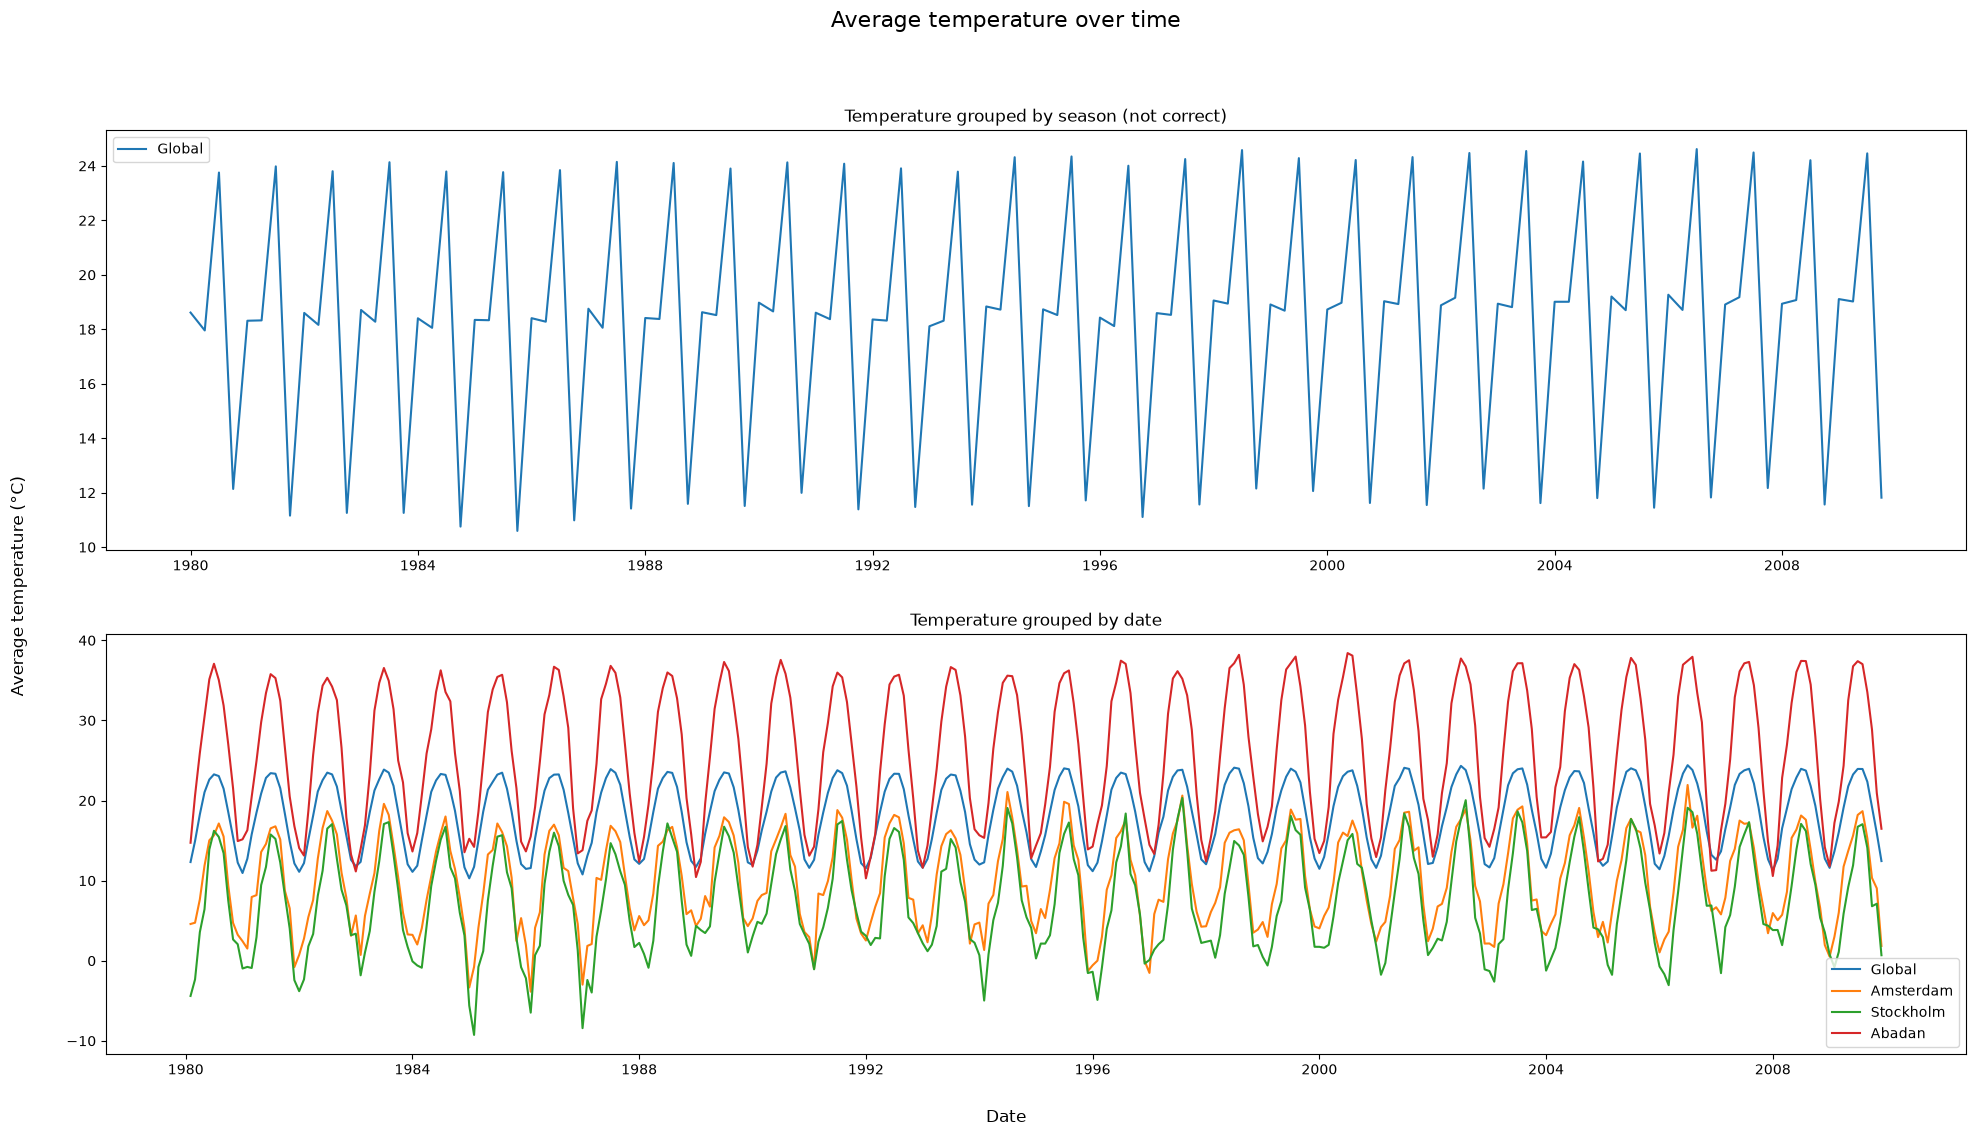

In [8]:
min_date = "1980-01-01"
max_date = "2010-01-01"

df_city_filter_date = df_city[
    (df_city["dt"] > min_date)
    & (df_city["dt"] < max_date)
]

df_city_sorted = df_city_filter_date.sort_values(["City", "Country", "dt"])
df_city_sorted = create_season_column(df_city_sorted)

# Temperature per city/global
df_city_vis_global_season = df_city_sorted[["year_season", "AverageTemperature"]].groupby(["year_season"]).mean()
df_city_vis_global_dates = df_city_sorted[["dt", "AverageTemperature"]].groupby(["dt"]).mean()
amsterdam_temps = df_city_sorted[df_city_sorted["City"] == "Amsterdam"]["AverageTemperature"]
stockholm_temps = df_city_sorted[df_city_sorted["City"] == "Stockholm"]["AverageTemperature"]
madrid_temps = df_city_sorted[df_city_sorted["City"] == "Madrid"]["AverageTemperature"]
kaapstad_temps = df_city_sorted[df_city_sorted["City"] == "Cape Town"]["AverageTemperature"]
sydney_temps = df_city_sorted[df_city_sorted["City"] == "Sydney"]["AverageTemperature"]
abadan_temps = df_city_sorted[df_city_sorted["City"] == "Abadan"]["AverageTemperature"]

year_seasons = df_city_sorted["year_season"].unique()
years = df_city_sorted["year"].unique()
dates = df_city_sorted["dt"].unique()

fig, ax = plt.subplots(2,1, figsize=(24,12))
fig.suptitle("Average temperature over time", fontsize=16)
fig.supylabel("Average temperature (°C)", x=0.085)
fig.supxlabel("Date", y=0.05)

# Upper subplot
ax[0].plot(df_city_vis_global_season.index, df_city_vis_global_season["AverageTemperature"], label="Global")

tick_positions = range(0, len(year_seasons), 16)
tick_labels = [year_seasons[i].split("_")[0] for i in tick_positions]
ax[0].set_xticks(tick_positions)
ax[0].set_xticklabels(tick_labels)
ax[0].legend()
ax[0].set_title("Temperature grouped by season (not correct)")


# Lower subplot
ax[1].plot(dates, df_city_vis_global_dates, label="Global")
ax[1].plot(dates, amsterdam_temps, label="Amsterdam")
ax[1].plot(dates, stockholm_temps, label="Stockholm")
ax[1].plot(dates, abadan_temps, label="Abadan")
# ax[1].plot(dates, madrid_temps, label="Madrid")
# ax[1].plot(dates, kaapstad_temps, label="Cape Town")
# ax[1].plot(dates, sydney_temps, label="Sydney")

ax[1].legend()
ax[1].set_title("Temperature grouped by date")

plt.show()

## Country data